<a href="https://colab.research.google.com/github/emilioan55/TAREAS-MAESTRIA/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: EMILIO ANDRES MENDOZA KAPLAN
*   MATRÍCULA: A00042485

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [46]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer


1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [47]:
from google.colab import drive

# Esto monta mi Google Drive en la carpeta '/content/drive'
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
#Carga el archivo guardado en mi Drive y hacer que 'id' sea el índice
ruta_archivo = '/content/drive/MyDrive/heart_disease.csv'
cardio_df = pd.read_csv(ruta_archivo, index_col='id')

# Muestra los primeros registros
cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**La columna "id" es el índice del data frame.**

In [49]:
# Mostrar la información general
print("--- Resumen de info() ---")
cardio_df.info()

# Determinar número de columnas numéricas y de texto
cols_numericas = cardio_df.select_dtypes(include=['int64', 'float64']).shape[1]
cols_texto = cardio_df.select_dtypes(include=['object', 'category']).shape[1]

print("\n--- Conteo de Columnas ---")
print(f"Columnas numéricas: {cols_numericas}")
print(f"Columnas de texto: {cols_texto}")

--- Resumen de info() ---
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB

--- Conteo de Columnas ---
Columnas numéricas: 7
Columnas de texto: 8


**7 columnas tienen datos numéricos y 8 de texto**

In [50]:
# Valores únicos por columna
print("--- Cantidad de valores únicos por columna ---")
print(cardio_df.nunique())

--- Cantidad de valores únicos por columna ---
age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg       3
thalch      119
exang         2
oldpeak      53
slope         3
ca            4
thal          3
num           5
dtype: int64


**La cantidad de valores únicos por cada columna son:**

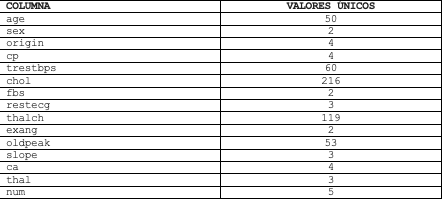




2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

**La variable numérica "ca" (Número de vasos principales coloreados por fluoroscopía) es categórica y ordinal  con valores de 0 al 3 con mayor grado de gravedad a número mayor y l avariable "num" con valores del 0 al 4 también es categírica y oridinal por las mismas razones.**

In [51]:
# Define las categorías ordenadas
orden_ca = [0.0, 1.0, 2.0, 3.0]
orden_num = [0, 1, 2, 3, 4]

# Convierte 'ca' y 'num' a tipo Categorical ordinal
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=orden_ca, ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=orden_num, ordered=True)

# 4. Verificar el cambio de tipos de datos
print("\n--- Tipos de datos actualizados ---")
print(cardio_df[['ca', 'num']].dtypes)


--- Tipos de datos actualizados ---
ca     category
num    category
dtype: object


**"ca" y "num" quedan clasificados como categóricos y ordenados de acuerdo con la descripción de los datos**

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [52]:
# Estadísticas descriptivas para variables NUMÉRICAS
# (incluye media, std, min, max, cuartiles, además de sesgo y curtosis)
cols_numericas = cardio_df.select_dtypes(include=['int64', 'float64'])

stats_num = cols_numericas.describe().T
stats_num['skewness'] = cols_numericas.skew()
stats_num['kurtosis'] = cols_numericas.kurtosis()

print("==================================================")
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES NUMÉRICAS")
print("==================================================")
display(stats_num)

# Estadísticas descriptivas y tablas de frecuencia para variables CATEGÓRICAS
# (incluye las de tipo 'object', 'bool' y 'category' creadas previamente)
cols_categoricas = cardio_df.select_dtypes(include=['object', 'category', 'bool'])

print("\n==================================================")
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CATEGÓRICAS")
print("==================================================")
display(cols_categoricas.describe().T)

print("\n==================================================")
print("TABLAS DE FRECUENCIA PARA VARIABLES CATEGÓRICAS")
print("==================================================")

for col in cols_categoricas.columns:
    print(f"\n--- Frecuencias para la columna: {col} ---")

    # Frecuencia absoluta y relativa (%)
    frec_abs = cardio_df[col].value_counts(dropna=False)
    frec_rel = cardio_df[col].value_counts(dropna=False, normalize=True) * 100

    tabla_frec = pd.DataFrame({
        'Frecuencia Absoluta': frec_abs,
        'Porcentaje (%)': frec_rel.round(2)
    })

    display(tabla_frec)

ESTADÍSTICAS DESCRIPTIVAS - VARIABLES NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834



ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CATEGÓRICAS


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411



TABLAS DE FRECUENCIA PARA VARIABLES CATEGÓRICAS

--- Frecuencias para la columna: sex ---


...

,Frecuencia Absoluta,Porcentaje (%)
ca,,
NaN,609,66.34
0.0,181,19.72
1.0,67,7.30
2.0,41,4.47
3.0,20,2.18



--- Frecuencias para la columna: thal ---


,Frecuencia Absoluta,Porcentaje (%)
thal,,
NaN,484,52.72
normal,196,21.35
reversable defect,192,20.92
fixed defect,46,5.01



--- Frecuencias para la columna: num ---


,Frecuencia Absoluta,Porcentaje (%)
num,,
0,411,44.77
1,263,28.65
2,109,11.87
3,107,11.66
4,28,3.05


**En las tablas se muestran las estadísticas descriptivas para las variadbles numéricas y para las categórucas de acuerdo con lo solicitado**

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

--- Porcentaje de valores faltantes por columna ---
          Valores Faltantes (%)
ca                        66.34
thal                      52.72
slope                     33.55
fbs                        9.69
oldpeak                    6.75
trestbps                   6.43
thalch                     5.99
exang                      5.99
chol                       3.27
sex                        0.00
origin                     0.00
cp                         0.00
age                        0.00
restecg                    0.00
num                        0.00

Columnas eliminadas por superar el 30% de faltantes: ['slope', 'ca', 'thal']


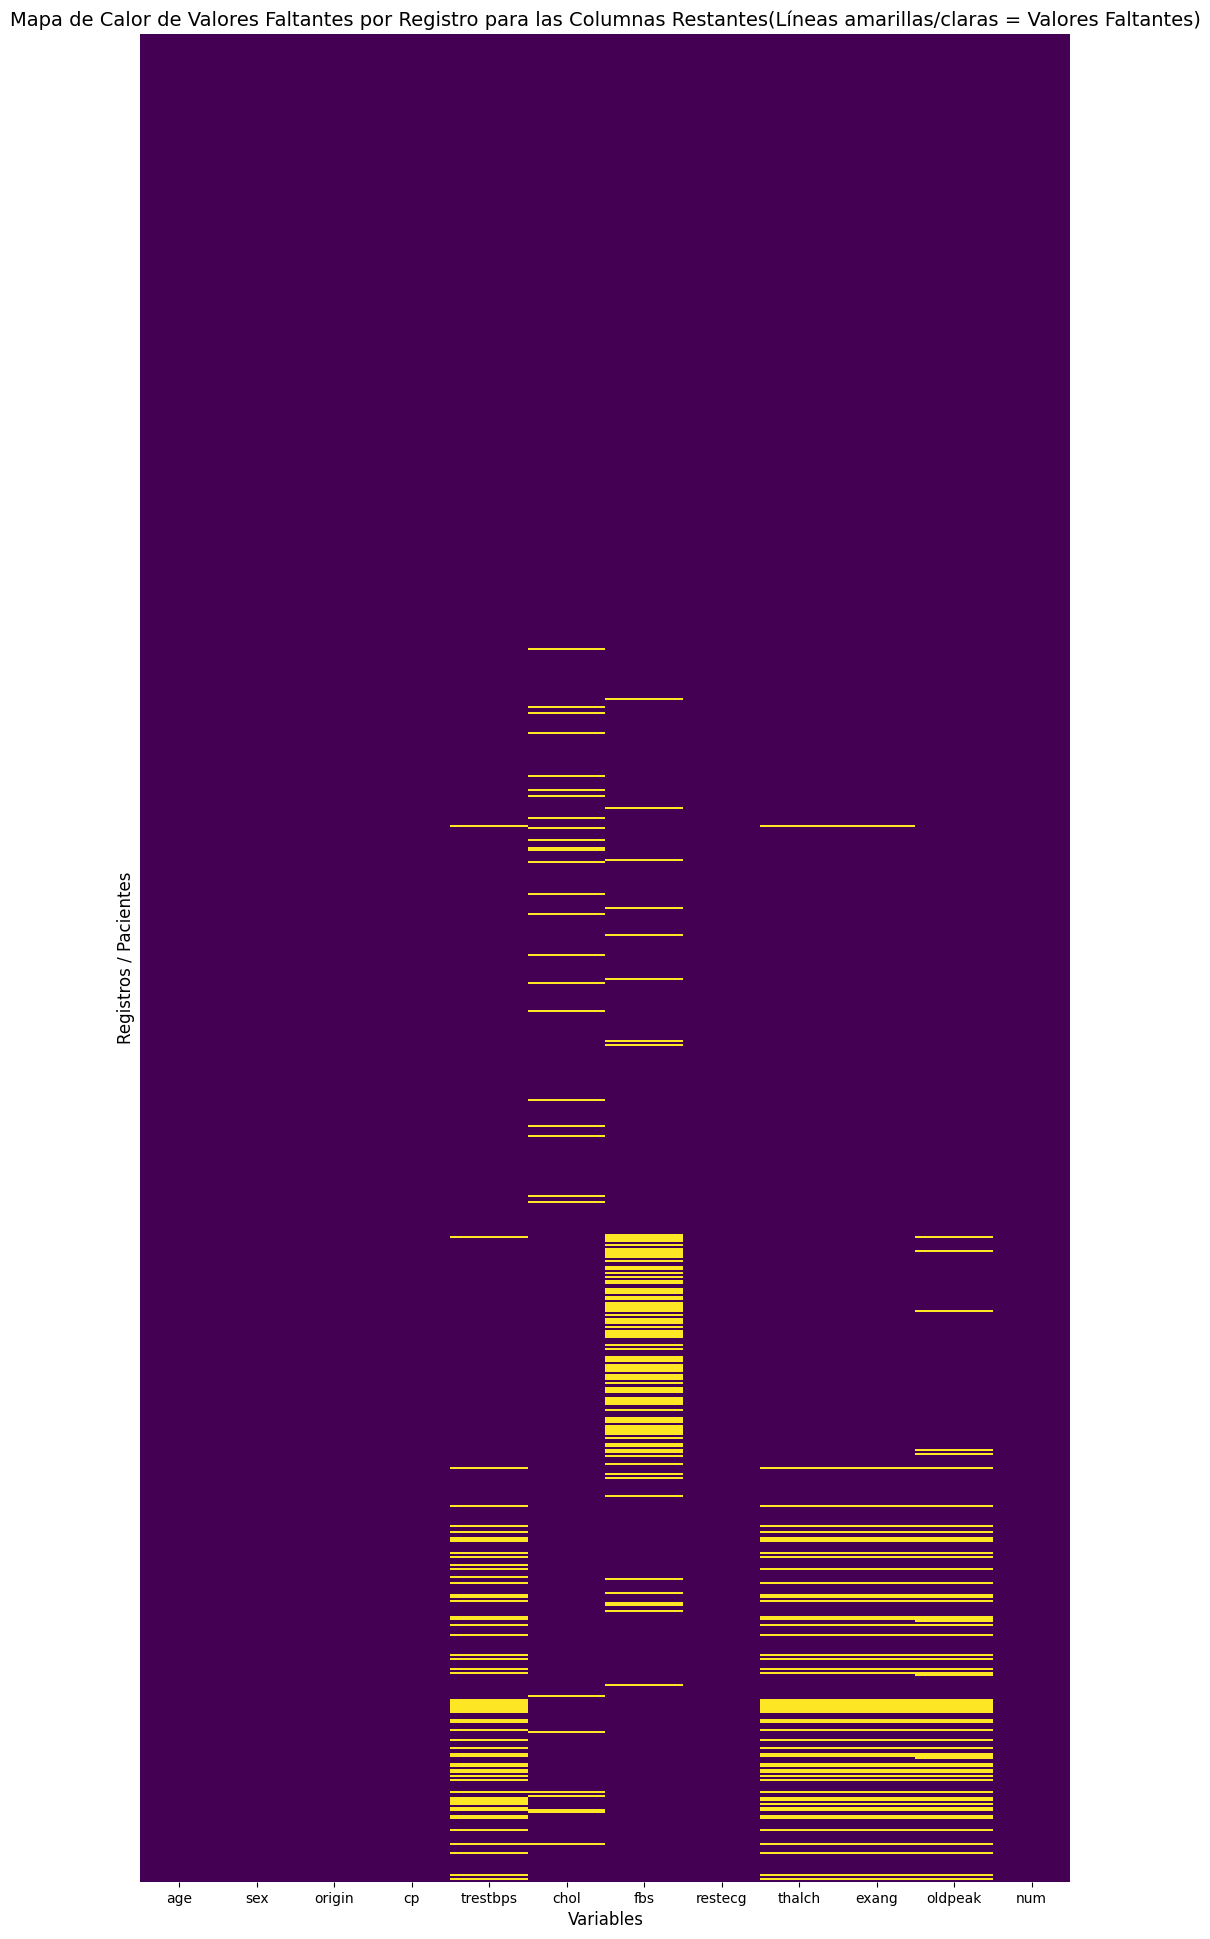


Número de pacientes con múltiples valores faltantes simultáneos: 59


In [53]:
# Calcula el porcentaje de valores faltantes por columna
porcentaje_faltantes = (cardio_df.isna().mean() * 100).round(2)
df_faltantes = pd.DataFrame({
    'Valores Faltantes (%)': porcentaje_faltantes
}).sort_values(by='Valores Faltantes (%)', ascending=False)

print("--- Porcentaje de valores faltantes por columna ---")
print(df_faltantes)

# Elimina columnas con más del 30% de valores faltantes
columnas_a_eliminar = porcentaje_faltantes[porcentaje_faltantes > 30].index.tolist()
print(f"\nColumnas eliminadas por superar el 30% de faltantes: {columnas_a_eliminar}")

cardio_df = cardio_df.drop(columns=columnas_a_eliminar)

# Crea mapa de calor de valores faltantes en las columnas restantes
plt.figure(figsize=(12, 24))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Faltantes por Registro para las Columnas Restantes(Líneas amarillas/claras = Valores Faltantes)', fontsize=14)
plt.xlabel('Variables', fontsize=12)
plt.ylabel('Registros / Pacientes', fontsize=12)
plt.show()

# Identifica la concurrencia de valores faltantes simultáneos
# Filtramos filas que tienen más de un valor nulo al mismo tiempo
faltantes_simultaneos = cardio_df[cardio_df.isna().sum(axis=1) > 1]
print(f"\nNúmero de pacientes con múltiples valores faltantes simultáneos: {len(faltantes_simultaneos)}")

**Las columnas eliminadas por superar el 30% de faltantes: ['slope', 'ca', 'thal']**

**Por la densidad de los datos faltantes y el tamaño de la gráfica prefiero contar los casos de pacientes con multiples valores faltantes simultáneos mediante código lo que hago a continuación**

In [54]:
# Identifica las variables con al menos 1 valor faltante
cols_con_nulos = cardio_df.columns[cardio_df.isna().any()].tolist()

print(f"Las columnas que presentan valores faltantes son ({len(cols_con_nulos)}):")
print(cols_con_nulos)
print("-" * 60)

# Filtra únicamente a los pacientes que tienen DOS O MÁS valores faltantes
df_multi_nulos = cardio_df[cardio_df.isna().sum(axis=1) >= 2].copy()

# Crea una etiqueta con la combinación exacta de columnas faltantes para cada paciente
def obtener_patron_nulos(row):
    faltantes = row.index[row.isna()].tolist()
    return " + ".join(faltantes)

df_multi_nulos['patron_faltantes'] = df_multi_nulos.apply(obtener_patron_nulos, axis=1)

# Cuenta cuántos pacientes están en cada caso
resumen_patrones = df_multi_nulos['patron_faltantes'].value_counts().reset_index()
resumen_patrones.columns = ['Combinación de Variables Faltantes', 'Número de Pacientes']

print("=== PACIENTES CON 2 O MÁS VALORES FALTANTES SIMULTÁNEOS ===")
print(f"Total de pacientes en esta condición: {len(df_multi_nulos)}\n")
display(resumen_patrones)

Las columnas que presentan valores faltantes son (6):
['trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak']
------------------------------------------------------------
=== PACIENTES CON 2 O MÁS VALORES FALTANTES SIMULTÁNEOS ===
Total de pacientes en esta condición: 59



,Combinación de Variables Faltantes,Número de Pacientes
0,trestbps + thalch + exang + oldpeak,51
1,trestbps + chol + thalch + exang + oldpeak,3
2,fbs + oldpeak,3
3,trestbps + thalch + exang,1
4,trestbps + fbs + oldpeak,1


**Los registros de pacientes que presentan valores faltantes simultáneamente se concentrab en un grupo que incluye la presion arterial al ingreso y resultados de una prueba de esfuerzo, de acuerdo con la descripción de los datos.**

****

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [55]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [56]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

 ANÁLISIS DE VARIABLES NUMÉRICAS VS FALTANTES EN THALCH

--- 1. Variable: AGE (Edad) ---


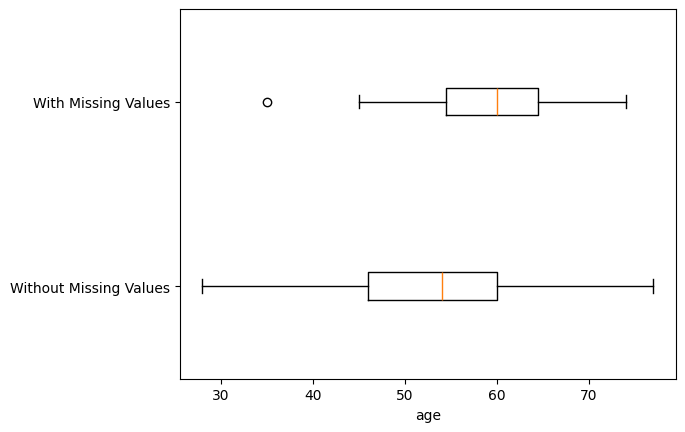

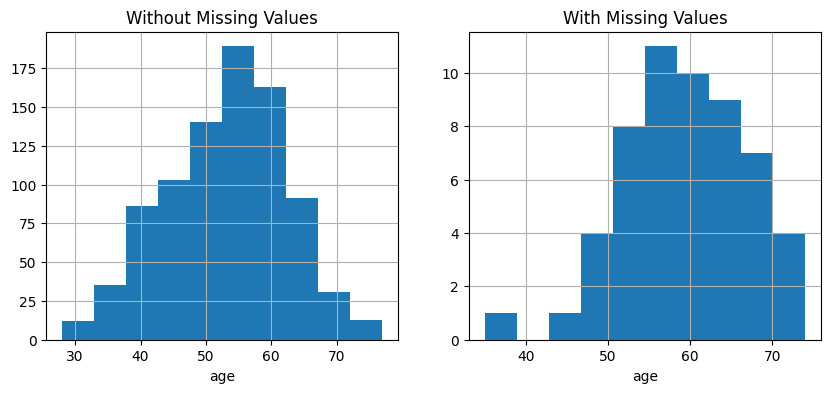

p-value of t-test: 1.5041244185890902e-06

--- 2. Variable: CHOL (Colesterol) ---


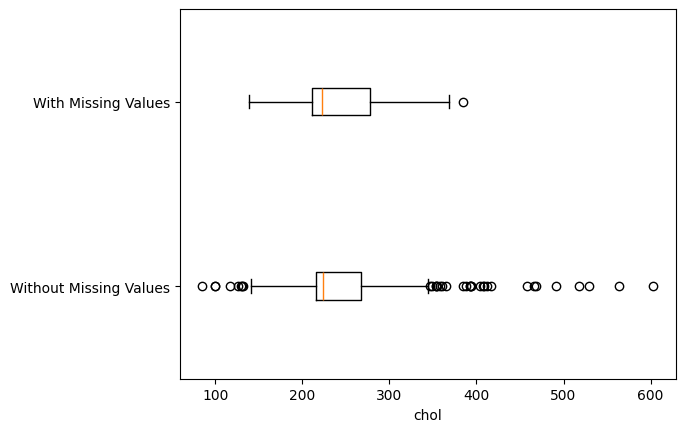

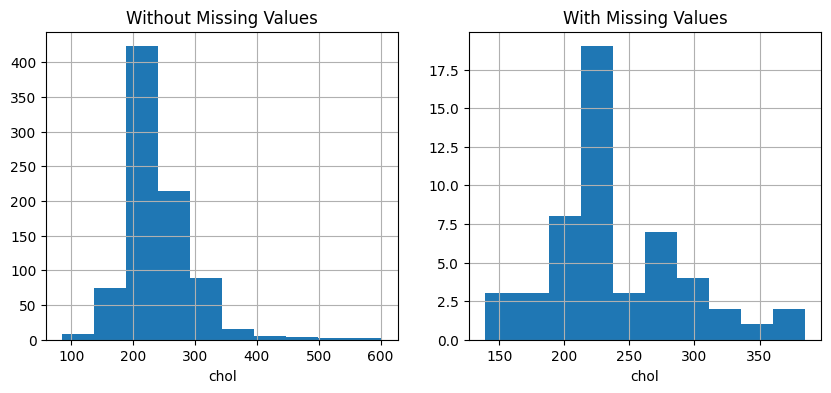

p-value of t-test: 0.7165289974295672

 ANÁLISIS DE VARIABLES CATEGÓRICAS VS FALTANTES EN THALCH

--- 3. Variable: RESTECG (ECG en reposo) ---


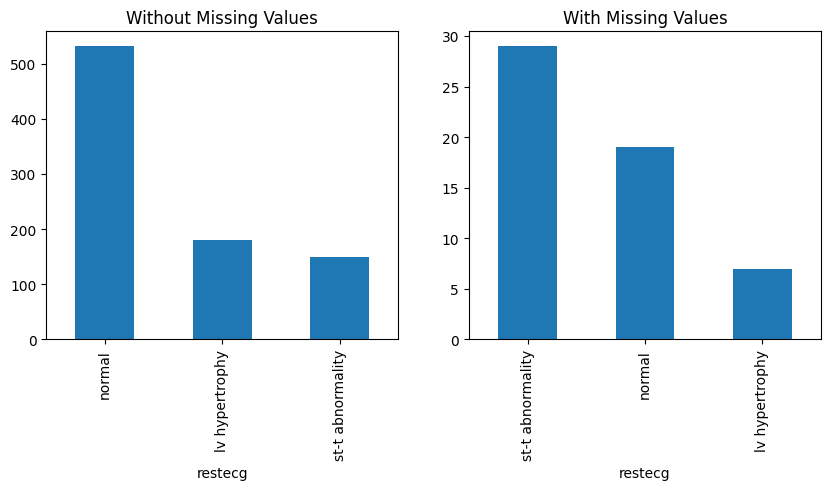

p-value of Chi_squared test: 1.1472889573985467e-09

--- 4. Variable: CP (Tipo de dolor de pecho) ---


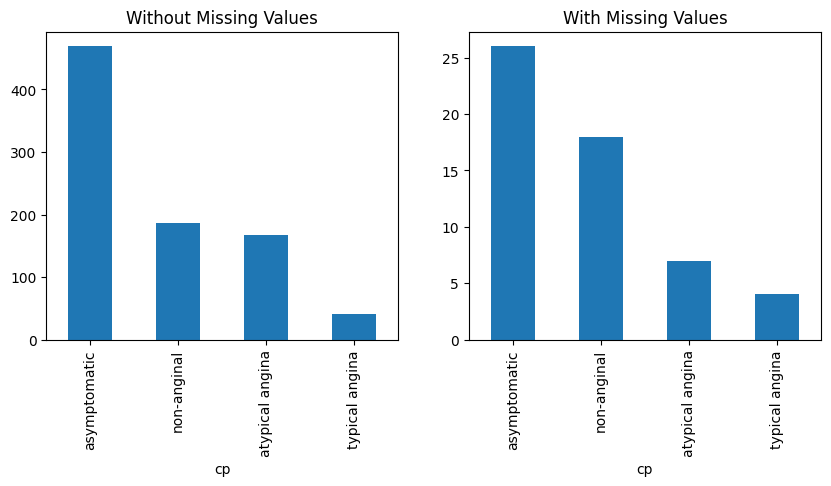

p-value of Chi_squared test: 0.15420097177251701


In [57]:
# Crea la máscara booleana (True si falta 'thalch', False si sí está el dato)
bm_thalch = cardio_df['thalch'].isnull()

print("======================================================")
print(" ANÁLISIS DE VARIABLES NUMÉRICAS VS FALTANTES EN THALCH")
print("======================================================")

print("\n--- 1. Variable: AGE (Edad) ---")
Diagnose_MV_Numerical(cardio_df, 'age', bm_thalch)

print("\n--- 2. Variable: CHOL (Colesterol) ---")
Diagnose_MV_Numerical(cardio_df, 'chol', bm_thalch)

print("\n========================================================")
print(" ANÁLISIS DE VARIABLES CATEGÓRICAS VS FALTANTES EN THALCH")
print("========================================================")

print("\n--- 3. Variable: RESTECG (ECG en reposo) ---")
Diagnose_MV_Categorical(cardio_df, 'restecg', bm_thalch)

print("\n--- 4. Variable: CP (Tipo de dolor de pecho) ---")
Diagnose_MV_Categorical(cardio_df, 'cp', bm_thalch)

**Conclusiones del Análisis de Valores Faltantes:**

Al evaluar la dependencia de los valores nulos en la variable thalch frente a otras variables del conjunto de datos, se demostró que la ausencia de información no es un evento aleatorio independiente.

Las pruebas estadísticas confirmaron diferencias significativas (p < 0.05) al cruzar la variable indicadora de faltantes en thalch con la variable numérica age y la variable categórica cp. Esto demuestra que la probabilidad de omisión de datos en thalch está correlacionada con los valores de dichas columnas.

Por el contrario, el análisis bivariado frente a chol y restecg arrojó valores p > 0.05, demostrando que estas variables son estadísticamente independientes de la presencia o ausencia de datos en thalch.

El mecanismo de los datos faltantes se clasifica como MAR (Missing at Random). El patrón MCAR (Missing Completely at Random) queda descartado, ya que requeriría una independencia estadística total frente a todas las demás variables del dataframe (p > 0.05 global). Dado que las pruebas T-Student y Chi-cuadrada evidencian que variables observadas (age y cp, ambas con p < 0.05) explican de manera significativa la distribución de los valores faltantes de thalch, se cumple matemáticamente con el criterio estadístico de MAR.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

/tmp/ipykernel_551/1601659152.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.mode().iloc[0]))
/tmp/ipykernel_551/1601659152.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.mode().iloc[0]))


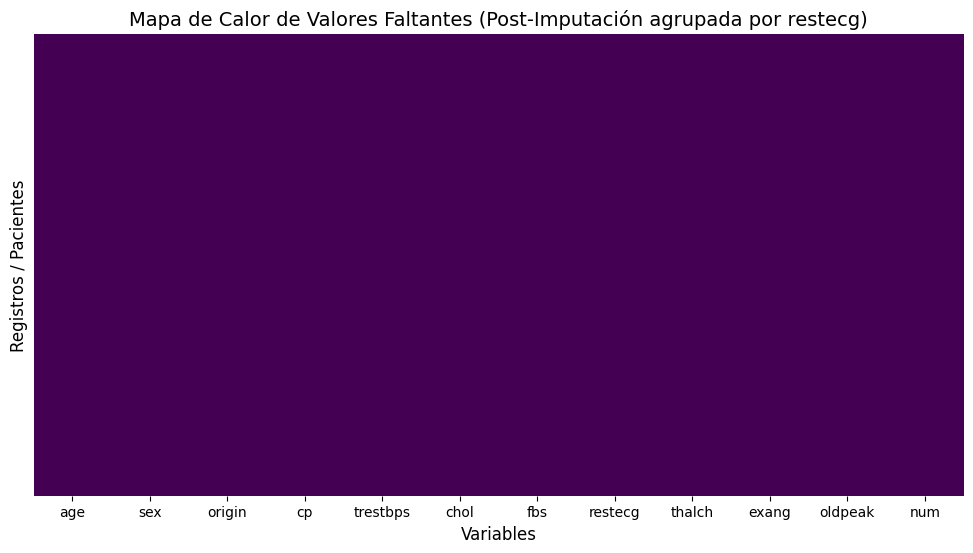

In [58]:
# Define las variables a imputar según su tipo de dato
# (Estas son las variables que mostraron concurrencia de faltantes previamente)
cols_num_imputar = ['trestbps', 'chol', 'thalch', 'oldpeak']
cols_cat_imputar = ['fbs', 'exang']

# Imputación para variables NUMÉRICAS utilizando la Mediana
for col in cols_num_imputar:
    if col in cardio_df.columns:
        cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# Imputación para variables CATEGÓRICAS/BOOLEANAS utilizando la Moda
for col in cols_cat_imputar:
    if col in cardio_df.columns:
        # Usamos .mode().iloc[0] para extraer el valor más frecuente del grupo
        cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.mode().iloc[0]))

# Vuelvo a generar el mapa de calor para verificar
plt.figure(figsize=(12, 6))
# Usamos un mapa de colores donde los nulos resalten (si los hay)
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Faltantes (Post-Imputación agrupada por restecg)', fontsize=14)
plt.xlabel('Variables', fontsize=12)
plt.ylabel('Registros / Pacientes', fontsize=12)
plt.show()

**El mapa de calor muestra que ya no existen valores faltantes en el data frame, agrupados por "resteceg" después de la imputación de valores conforme lo solicitado**

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [59]:
from sklearn.impute import SimpleImputer

# Identifico las variables que aún tienen valores faltantes
# (Esto asume que aún tienes columnas con nulos antes de este paso, o que se te pide aplicarlo a ciertas columnas)
cols_con_nulos = cardio_df.columns[cardio_df.isna().any()].tolist()
print(f"Columnas con nulos antes de SimpleImputer: {cols_con_nulos}")

# Separo esas columnas en numéricas y categóricas para aplicar distintas estrategias
cols_num_restantes = cardio_df[cols_con_nulos].select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat_restantes = cardio_df[cols_con_nulos].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Imputación de variables NUMÉRICAS usando la MEDIANA
if len(cols_num_restantes) > 0:
    imputer_num = SimpleImputer(strategy='median')
    # Aplicamos fit_transform y guardamos los resultados de vuelta en el dataframe
    cardio_df[cols_num_restantes] = imputer_num.fit_transform(cardio_df[cols_num_restantes])
    print(f"Variables numéricas imputadas con la mediana: {cols_num_restantes}")

# Imputación de variables CATEGÓRICAS usando la MODA ('most_frequent')
if len(cols_cat_restantes) > 0:
    imputer_cat = SimpleImputer(strategy='most_frequent')
    cardio_df[cols_cat_restantes] = imputer_cat.fit_transform(cardio_df[cols_cat_restantes])
    print(f"Variables categóricas imputadas con el valor más frecuente: {cols_cat_restantes}")

# Verificación final
print("\nVerificación final de nulos en todo el dataset:")
print(cardio_df.isna().sum())

Columnas con nulos antes de SimpleImputer: []

Verificación final de nulos en todo el dataset:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64


**Justificación para las variables Numéricas (strategy='median'):**

Para la imputación de las variables numéricas continuas, se eligió la estrategia de la mediana en lugar de la media. Los conjuntos de datos suelen presentar distribuciones asimétricas o outliers. La media es sumamente sensible a estos valores extremos, lo que podría desplazar artificialmente la estimación del centro de los datos. Por el contrario, la mediana proporciona una medida de tendencia central mucho más robusta y representativa de la distribución subyacente.

**Justificación para las variables Categóricas/Booleanas (strategy='most_frequent'):**

Para las variables discretas, nominales u ordinales, se aplicó la estrategia de la moda (most_frequent). Matemáticamente, las medidas de tendencia central continuas (como la media o la mediana) no son aplicables a variables cualitativas. Imputar con la categoría de mayor frecuencia relativa es el enfoque estadístico estándar para tratar los valores nulos en este tipo de datos, lo que minimiza el error de clasificación y preserva en la mayor medida posible la distribución de probabilidades original.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

 EXTRACCIÓN DE VALORES ATÍPICOS (MÉTODO GRÁFICO)

Variable 'age': 0 valores atípicos encontrados.
   (Sin valores atípicos)

Variable 'trestbps': 27 valores atípicos encontrados.
   Valores: [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]

Variable 'chol': 44 valores atípicos encontrados.
   Valores: [85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131.0, 132.0, 139.0, 141.0, 142.0, 342.0, 342.0, 342.0, 344.0, 347.0, 349.0, 353.0, 354.0, 355.0, 358.0, 360.0, 365.0, 369.0, 384.0, 385.0, 388.0, 392.0, 393.0, 394.0, 394.0, 404.0, 407.0, 409.0, 412.0, 417.0, 458.0, 466.0, 468.0, 491.0, 518.0, 529.0, 564.0, 603.0]

Variable 'thalch': 2 valores atípicos encontrados.
   Valores: [60.0, 63.0]

Variable 'oldpeak': 16 valores atípicos encontrados.
   Valores: [-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.2, 4.2, 4.4, 5.0, 5.6, 6.2]



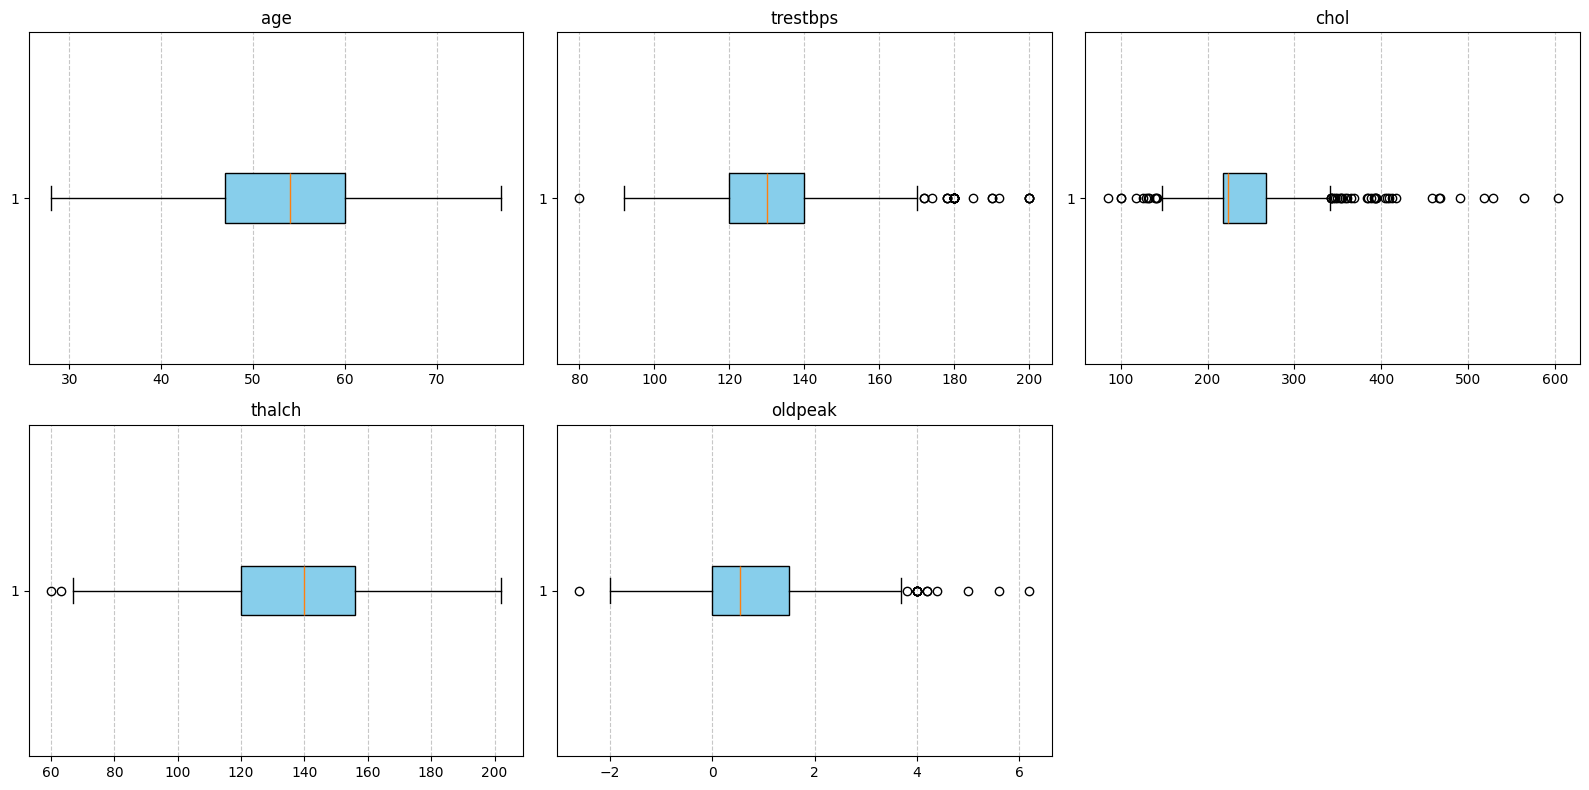

In [60]:
# Selecciono solo las variables continuas/numéricas
cols_num = cardio_df.select_dtypes(include=['int64', 'float64']).columns
n_cols = len(cols_num)

# Configuro la cuadrícula para 2 renglones
nrows = 2
ncols = math.ceil(n_cols / nrows)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 8))
axes = axes.flatten()

print("==================================================")
print(" EXTRACCIÓN DE VALORES ATÍPICOS (MÉTODO GRÁFICO)")
print("==================================================\n")

# Dibujo los boxplots iterando por cada columna
for i, col in enumerate(cols_num):
    bp = axes[i].boxplot(cardio_df[col].dropna(), patch_artist=True, vert=False, boxprops=dict(facecolor='skyblue'))
    axes[i].set_title(f'{col}', fontsize=12)
    axes[i].grid(axis='x', linestyle='--', alpha=0.7)

    # Extraemos los datos y los convertimos a una lista normal de Python con .tolist()
    outliers = bp['fliers'][0].get_xdata().tolist()

    print(f"Variable '{col}': {len(outliers)} valores atípicos encontrados.")
    if len(outliers) > 0:
        # Imprime la lista ya ordenada y sin la etiqueta de numpy
        print(f"   Valores: {sorted(outliers)}\n")
    else:
        print("   (Sin valores atípicos)\n")

# Oculto los espacios vacíos
for j in range(n_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**REPORTE DE VALORES ATÍPICOS ENCONTRADOS**


Variable 'age': 0 valores atípicos encontrados.
   (Sin valores atípicos)

Variable 'trestbps': 27 valores atípicos encontrados.
   Valores: [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]

Variable 'chol': 44 valores atípicos encontrados.
   Valores: [85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131.0, 132.0, 139.0, 141.0, 142.0, 342.0, 342.0, 342.0, 344.0, 347.0, 349.0, 353.0, 354.0, 355.0, 358.0, 360.0, 365.0, 369.0, 384.0, 385.0, 388.0, 392.0, 393.0, 394.0, 394.0, 404.0, 407.0, 409.0, 412.0, 417.0, 458.0, 466.0, 468.0, 491.0, 518.0, 529.0, 564.0, 603.0]

Variable 'thalch': 2 valores atípicos encontrados.
   Valores: [60.0, 63.0]

Variable 'oldpeak': 16 valores atípicos encontrados.
   Valores: [-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.2, 4.2, 4.4, 5.0, 5.6, 6.2]

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [61]:
# Calcula el Primer Cuartil (Q1 - 25%) y el Tercer Cuartil (Q3 - 75%) para 'trestbps'
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)

# Calcula el Rango Intercuartílico (IQR)
IQR = Q3 - Q1

# Define los límites inferior y superior (1.5 * IQR)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("==================================================")
print(" CÁLCULO DE OUTLIERS POR EL MÉTODO IQR (trestbps)")
print("==================================================")
print(f"Q1 (25%): {Q1}")
print(f"Q3 (75%): {Q3}")
print(f"IQR: {IQR}")
print(f"Límite Inferior: {limite_inferior}")
print(f"Límite Superior: {limite_superior}\n")

# Filtra los valores atípicos fuera de ese rango
outliers_iqr = cardio_df[(cardio_df['trestbps'] < limite_inferior) | (cardio_df['trestbps'] > limite_superior)]['trestbps']

print(f"Total de valores atípicos encontrados por IQR: {len(outliers_iqr)}")
print(f"Valores atípicos exactos: {sorted(outliers_iqr.tolist())}")

 CÁLCULO DE OUTLIERS POR EL MÉTODO IQR (trestbps)
Q1 (25%): 120.0
Q3 (75%): 140.0
IQR: 20.0
Límite Inferior: 90.0
Límite Superior: 170.0

Total de valores atípicos encontrados por IQR: 27
Valores atípicos exactos: [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]


**Coincide exactamente. Mediante ambos métodos se encuentran 27 valores atípicos para trestbps.**

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros originales: 918
Registros después de eliminar outliers en trestbps: 891
Se eliminaron 27 registros atípicos.


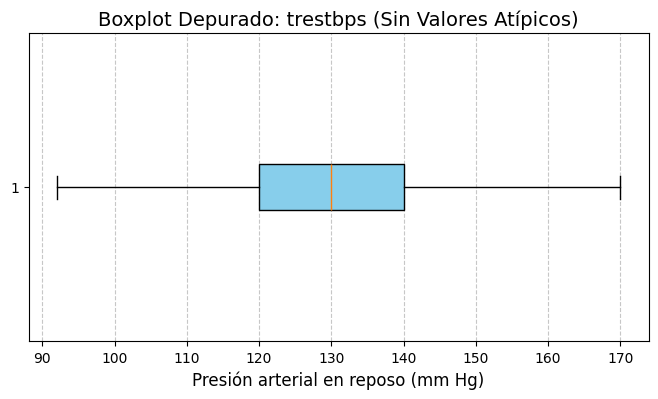

In [62]:
## Calcula Q1, Q3 e IQR para 'trestbps'
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1

# Defino los límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtro el DataFrame para conservar únicamente los registros dentro de los límites
cardio_df_depurado = cardio_df[(cardio_df['trestbps'] >= limite_inferior) & (cardio_df['trestbps'] <= limite_superior)].copy()

print(f"Registros originales: {len(cardio_df)}")
print(f"Registros después de eliminar outliers en trestbps: {len(cardio_df_depurado)}")
print(f"Se eliminaron {len(cardio_df) - len(cardio_df_depurado)} registros atípicos.")

# Dibujo el boxplot final para visualizar la distribución depurada de 'trestbps'
plt.figure(figsize=(8, 4)) # Altura reducida para que luzca mejor en horizontal
plt.boxplot(cardio_df_depurado['trestbps'].dropna(), patch_artist=True, boxprops=dict(facecolor='skyblue'), vert=False)
plt.title('Boxplot Depurado: trestbps (Sin Valores Atípicos)', fontsize=14)
plt.xlabel('Presión arterial en reposo (mm Hg)', fontsize=12) # Cambiado a xlabel
plt.grid(axis='x', linestyle='--', alpha=0.7) # Cuadrícula en el eje X
plt.show()

**Se muestra el boxplot ya sin valores atípicos**

**Bibliografía**

Jafari, R. (2022). *Hands-on data preprocessing in Python*. Packt Publishing.

**Declaración de uso de IA**

Google. (2026). Gemini (versión de octubre de 2026) [Modelo de lenguaje grande]. https://gemini.google.com

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---